In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv('car data.csv')

In [3]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
df.shape

(301, 9)

In [5]:
df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0


In [6]:
df.duplicated().sum()

np.int64(2)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [8]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [10]:
df = df.drop_duplicates()

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
#feature enginneering

In [13]:
current_year = 2026

df["Car_Age"] = current_year - df["Year"]

df[["Year", "Car_Age", "Selling_Price"]].head()

/tmp/ipykernel_2961/1075488488.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Car_Age"] = current_year - df["Year"]


,Year,Car_Age,Selling_Price
0,2014,12,3.35
1,2013,13,4.75
2,2017,9,7.25
3,2011,15,2.85
4,2014,12,4.60


In [14]:
df = df.drop("Year", axis=1)

In [15]:
#EDA

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

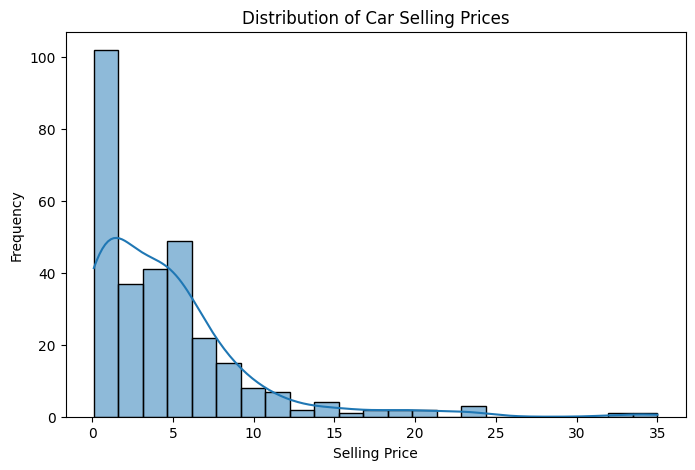

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Selling_Price"], kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()

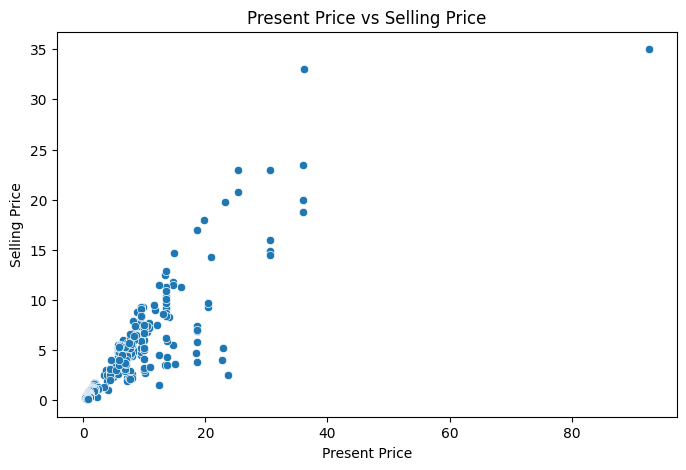

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Present_Price",
    y="Selling_Price"
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.show()


========== CATEGORICAL SUMMARY ==========

Car_Name:
Car_Name
city                  26
corolla altis         16
verna                 14
brio                  10
fortuner              10
                      ..
Honda Activa 125       1
Hero Hunk              1
Hero  Ignitor Disc     1
Hero  CBZ Xtreme       1
Bajaj  ct 100          1
Name: count, Length: 98, dtype: int64

Fuel_Type:
Fuel_Type
Petrol    239
Diesel     58
CNG         2
Name: count, dtype: int64

Selling_type:
Selling_type
Dealer        193
Individual    106
Name: count, dtype: int64

Transmission:
Transmission
Manual       260
Automatic     39
Name: count, dtype: int64

========== NUMERICAL COLUMNS ==========
['Selling_Price', 'Present_Price', 'Driven_kms', 'Owner', 'Car_Age']

========== NUMERICAL DISTRIBUTIONS ==========


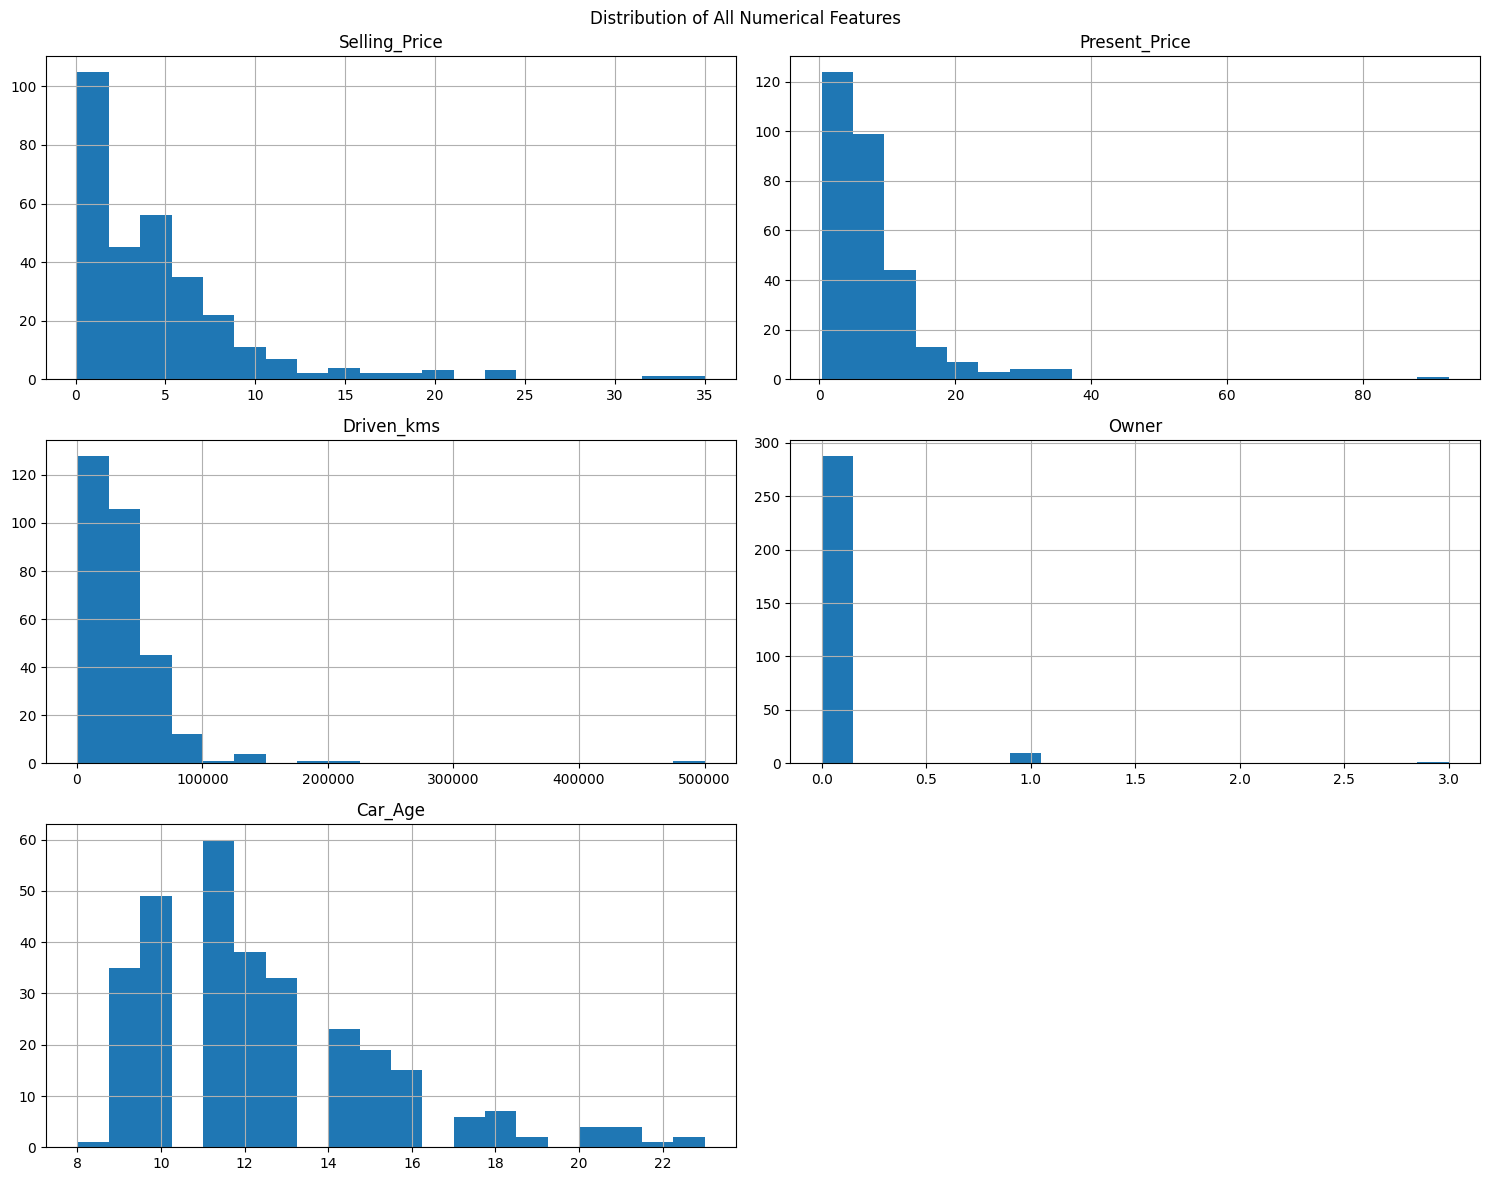


========== OUTLIER ANALYSIS ==========


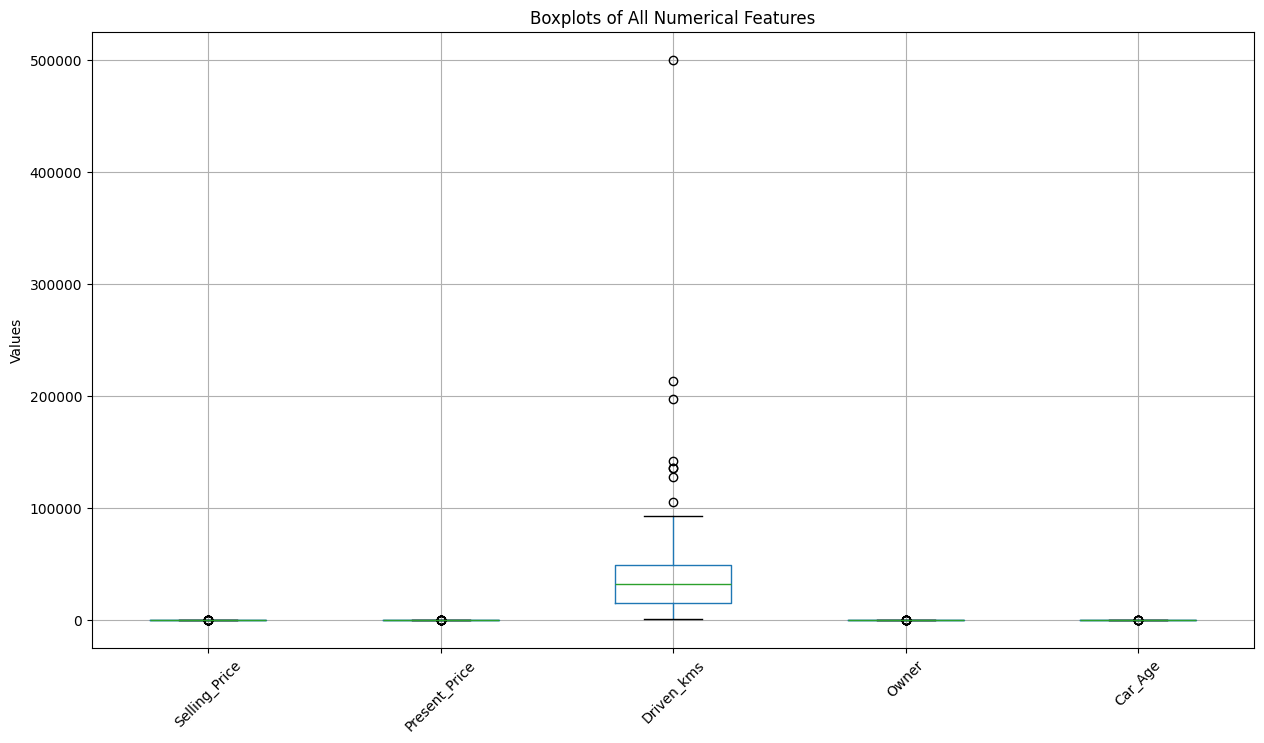


========== CORRELATION HEATMAP ==========


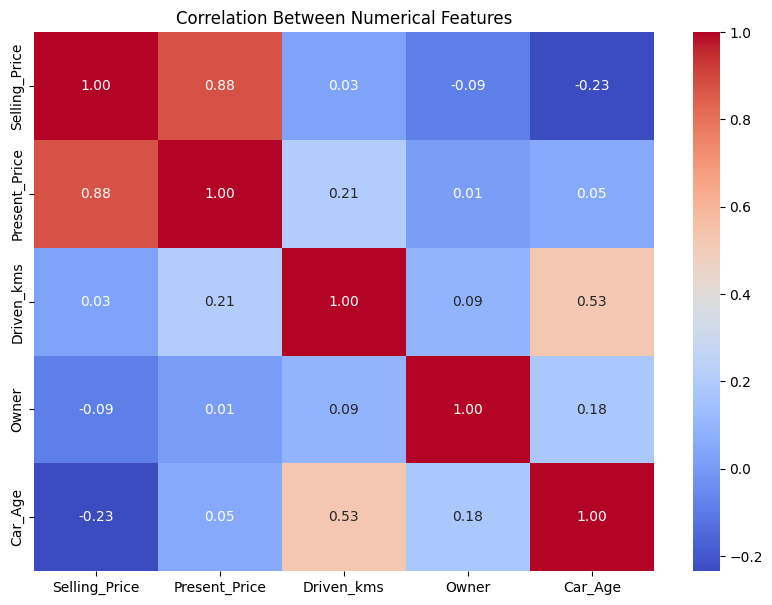


========== PAIRWISE RELATIONSHIPS ==========


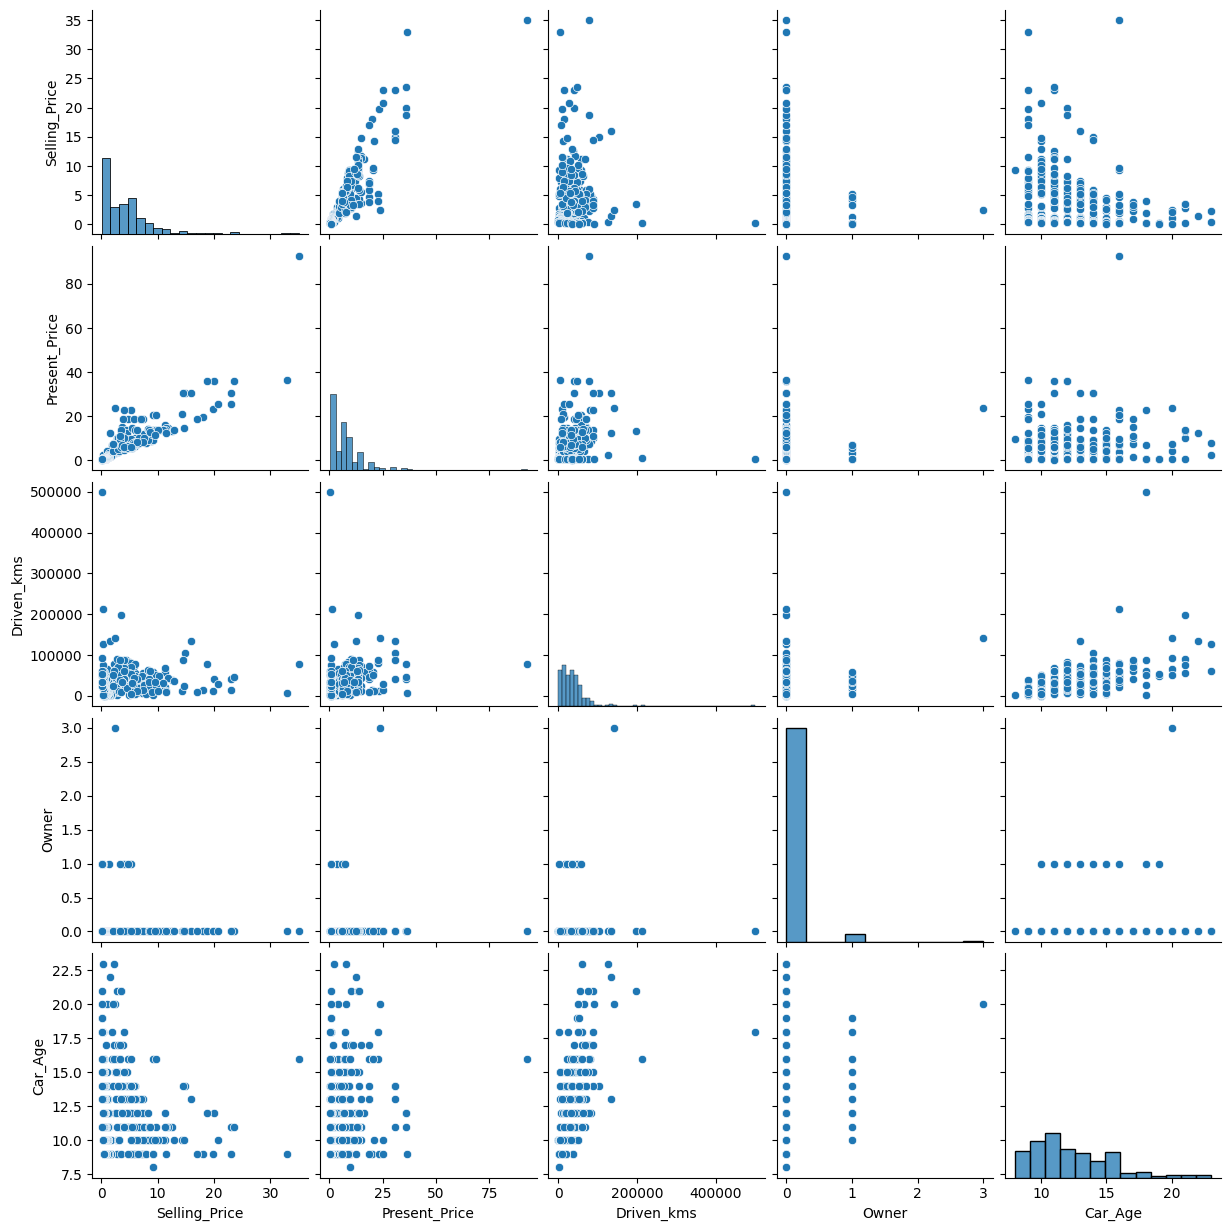

In [35]:
# ==============================
# EXPLORATORY DATA ANALYSIS
# ==============================

# 5. Categorical columns summary
print("\n========== CATEGORICAL SUMMARY ==========")

categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


# 8. Numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns

print("\n========== NUMERICAL COLUMNS ==========")
print(list(numerical_columns))


# 9. Histograms for ALL numerical columns
print("\n========== NUMERICAL DISTRIBUTIONS ==========")

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of All Numerical Features")
plt.tight_layout()
plt.show()


# 10. Boxplots for ALL numerical columns
print("\n========== OUTLIER ANALYSIS ==========")

plt.figure(figsize=(15, 8))

df[numerical_columns].boxplot()

plt.title("Boxplots of All Numerical Features")
plt.xticks(rotation=45)
plt.ylabel("Values")
plt.show()


# 11. Correlation heatmap
print("\n========== CORRELATION HEATMAP ==========")

plt.figure(figsize=(10, 7))

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()


# 12. Pairplot for numerical columns
print("\n========== PAIRWISE RELATIONSHIPS ==========")

sns.pairplot(
    df[numerical_columns]
)

plt.show()

In [24]:
# Check skewness of numerical columns

numerical_cols = X.select_dtypes(include=np.number).columns

skewness = X[numerical_cols].skew().sort_values(ascending=False)

print("Skewness of Numerical Features:")
print(skewness)

Skewness of Numerical Features:
Owner            7.590605
Driven_kms       6.418134
Present_Price    4.189255
Car_Age          1.236876
dtype: float64


In [26]:
# Make a copy of X
X_transformed = X.copy()

# Find highly right-skewed numerical features
skewed_features = skewness[skewness > 1].index

print("Highly right-skewed features:")
print(list(skewed_features))

# Apply log transformation
for col in skewed_features:
    X_transformed[col] = np.log1p(X_transformed[col])

Highly right-skewed features:
['Owner', 'Driven_kms', 'Present_Price', 'Car_Age']


In [27]:
# Skewness after transformation

new_skewness = X_transformed[numerical_cols].skew().sort_values(
    ascending=False
)

comparison = pd.DataFrame({
    "Before Transformation": skewness,
    "After Transformation": new_skewness
})

print(comparison)

               Before Transformation  After Transformation
Car_Age                     1.236876              0.725769
Driven_kms                  6.418134             -1.038844
Owner                       7.590605              5.717862
Present_Price               4.189255             -0.046436


In [28]:
# Apply transformation only to suitable continuous features

X_transformed = X.copy()

X_transformed["Car_Age"] = np.log1p(X_transformed["Car_Age"])
X_transformed["Present_Price"] = np.log1p(X_transformed["Present_Price"])

In [29]:
final_skewness = X_transformed[
    ["Car_Age", "Driven_kms", "Owner", "Present_Price"]
].skew()

print(final_skewness)

Car_Age          0.725769
Driven_kms       6.418134
Owner            7.590605
Present_Price   -0.046436
dtype: float64


In [30]:
X_processed = preprocessor.fit_transform(X)

In [31]:
X_processed = preprocessor.fit_transform(X_transformed)

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor

# -----------------------------------
# 1. Check skewness
# -----------------------------------

numerical_cols = X.select_dtypes(include=np.number).columns

skewness = X[numerical_cols].skew()

# -----------------------------------
# 2. Transform highly right-skewed features
# -----------------------------------

X_transformed = X.copy()

skewed_features = skewness[skewness > 1].index

for col in skewed_features:
    X_transformed[col] = np.log1p(X_transformed[col])

# -----------------------------------
# 3. Identify columns
# -----------------------------------

categorical_cols = X_transformed.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_transformed.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# -----------------------------------
# 4. Preprocessing
# -----------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

# -----------------------------------
# 5. Transform data
# -----------------------------------

X_processed = preprocessor.fit_transform(X_transformed)

# -----------------------------------
# 6. Train Random Forest
# -----------------------------------

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf.fit(X_processed, y)

# -----------------------------------
# 7. Feature importance
# -----------------------------------

feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                         Feature  Importance
0             num__Present_Price    0.873443
3                   num__Car_Age    0.084900
1                num__Driven_kms    0.022850
8   cat__Selling_type_Individual    0.004876
10      cat__Transmission_Manual    0.003591
6          cat__Fuel_Type_Petrol    0.003141
9    cat__Transmission_Automatic    0.003059
5          cat__Fuel_Type_Diesel    0.002769
7       cat__Selling_type_Dealer    0.000945
2                     num__Owner    0.000416
4             cat__Fuel_Type_CNG    0.000012
